# Case Study 17 — Unified Ranking of Sponsored and Organic Products: CTR/CVR Models, Calibration Across Populations, Blending and the A/B Test

**Priority:** ★★★ Must-visit · **Reference:** Case Study 17 — *Flipkart: unified ranking of sponsored and organic products on "Similar Products"* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Ads and Retail Media, Search and Recommendations, Product, Finance
**Data:** ⚠️ **SYNTHETIC** (D-17-01). Flipkart's impression logs and bids are confidential; this is a calibrated simulation with a hidden "true click model" (a digital twin).
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs17_ads_ranking_ctr_cvr.ipynb`

## 0. Executive Summary for Business

*(Synthetic impressions with a hidden click and order model (a digital twin), built on the design Flipkart documents for "Similar Products": sponsored and organic items competing under one score instead of pinned slots 2 and 5. Flipkart's data, exact score and auction are not public, and the company's lift chart gives no values. Written after the analysis.)*

- **The question:** can one pCTR/pCVR model rank ads and organic items together, is it calibrated for each, does it beat pinned slots on both organic orders and ad revenue, and how big must the A/B test be?
- **One model with an isAds flag and crosses discriminates slightly better and calibrates better for ads.** Overall AUC barely moves (0.7979 flag only vs 0.7993 with crosses), but ad AUC rises from 0.715 to 0.722 and ad log loss falls (Holm p = 0.04). The calibration slope for ads is **0.78** (CI 0.72 to 0.85) without crosses and **1.00** (0.91 to 1.08) with them. Gradient boosting is no better (0.7972).
- **Unified ranking beats pinned slots on both metrics (equal bid weight, lambda = 1).** Against 26.55 organic orders and ₹213.1 ad revenue per 1,000 requests, the crosses model gives **+14.2% organic orders** (CI 13.9% to 14.4%) and **+5.7% ad revenue** (5.1% to 6.3%). Without the flag, ad revenue is unchanged (+0.3%, CI -0.3% to 0.9%). The oracle with true probabilities reaches +21.2% and +10.9%.
- **Weights are a real trade-off.** Maximising ad revenue with the rule "organic orders must not fall" picks **lambda = 3**: **+44.1% ad revenue** (CI 43.6% to 44.5%) and **+1.5% organic orders** (1.2% to 1.8%), but the sponsored share of slots rises from 25% to **39.6%**. The organic-features model at its own lambda gives more organic orders (+3.2%) and less revenue (+37.6%).
- **Failures matter.** With 10% of ad scores failing to the 0.5 default, organic orders fall **7.0% below pinned**; a safe default (mean ad pCTR) holds them at +1.4%. Our circuit breaker (revert when all four ads are shown) reverts **42%** of requests even with no failure and cuts ad revenue lift from 44% to 11%, so it needs a better trigger.
- **A/B test:** the ad-revenue lift needs only about **2,500 requests per arm**. The organic-orders lift (+1.5%) needs about **2.8 million per arm**; at 1 million per arm power is 40%. The A/A false-positive rate checks out (5.0% and 3.0%).
- **Money (assumed value of ₹60 per organic order, 3 crore requests a day):** about **₹128 crore a year** (worst ₹41 crore, best ₹225 crore), of which ₹103 crore is ad revenue. Most of it comes from the high bid weight, which is a policy choice, not a model gain.
- **I recommend:** a model with the flag and crosses, calibrated per population, a safe default for failed scores with alerting, a staged A/B test of lambda (1 and 3 against pinned) and a rule that organic orders must not fall.

## 1. The Problem in Simple English

On a product page, the "Similar Products" strip shows a handful of items. Some are **organic** (chosen because they fit the shopper), some are **sponsored** (a seller paid to be shown, usually per click). The old design **pinned** sponsored items at fixed positions (slots 2 and 5) no matter what. That is predictable, but it shows a poor ad even where no ad fits (a pair of pocket scissors) and it limits good ads where several fit (a new smartphone).

The new idea is to let organic and sponsored items **compete for the same slots under one scoring rule**. The hard part is not the ranking; it is that clicks on ads and on organic items have **different base rates**. If the model says "4% chance of a click" for an ad that really gets 2%, the ranker will over-show ads, hurting shoppers and organic sellers without paying off.

Leaders and interviewers want to know:
1. Can one model predict click and purchase probability for **both** ads and organic items, and is it **calibrated** for each?
2. Does letting ads and organic items compete beat pinned slots on **both** organic orders and ad revenue, or does one pay for the other?
3. How should the **weights** between shopper value and ad revenue be chosen?
4. What happens when the model **fails** (the default 0.5 score) and how do we guard against it?
5. How big must the **A/B test** be to see the lift?

## 2. Reference from the Case File

### (a) What Flipkart did — *documented*

| Item | Documented fact (from the reference file) |
|---|---|
| Problem | Product-page widgets pinned sponsored items at fixed slots 2 and 5. The authors call this "safe, predictable, but ultimately sub-optimal". Goal: let sponsored and organic items compete for slots under one objective |
| Data | Historical impressions from both organic and ads pipelines, combined; organic feedback is "multi-fold" larger than ads. Co-browse and co-impression "pair stats", popularity; **27 key features** crossed with isAds. Ad bids/costs used in the sponsored score (exact formula not disclosed) |
| Approach | Funnel: candidate sourcing, a relevance-filtering stage (SGD classifier for the probability of conversion given impression), then a personalised online ranker (FTRL) with **separate CTR and CVR models**. One training set with an **isAds flag plus 2-way and 3-way crosses** of the 27 features with isAds. Separate organic and sponsored objective functions (organic: a weighted combination with tunable alpha and beta; sponsored adds bid cost components). Weights chosen by **offline simulation framed as multi-objective optimisation**. A **circuit breaker** reverts to pinned slots 2 and 5 if the organic ranker fails; the 0.5 default-score fallback could flood the page with ads |
| Validation | Offline grid: baseline organic-only features vs isAds flag only vs full crosses, on organic-only and ads-only test sets; metrics AUC, Request AUC, NDCG, MAP, MRR (the lift chart is an image, values not disclosed; text says the lift was larger for ads with organic about unchanged). Online high-mod A/B with cumulative exposures above **100 million**; test type and CIs not disclosed |
| Decision and impact | Scaled to 100% of Flipkart traffic and launched for "Similar Products". Company claim: "a statistically significant **(1.36%) increase in orders for organic products** and a **3.4% increase in bottomline Ads revenue**" |

**Source:** "The Science of Unified Ranking: Integrating Ads and Organic Recommendations", Flipkart Tech blog (Amar Kumar et al.), 4 Nov 2025. The exact auction or pricing mechanism is **not described**, so we attribute none: our sponsored value simply adds the bid per click.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 80,000 requests over 14 days, each with 12 organic and 4 sponsored candidates and a hidden true click/order model. Legacy logging pins two ads at slots 2 and 5 (so 75% of logged impressions are organic), with a 20% random-slotting exploration bucket (**our assumption**, so every candidate type is observed in every slot). Ads have a lower base rate and a weaker dependence on relevance than organic items; the request category changes how relevant ads are |
| Models | Logistic CTR models: organic-features only (no flag), flag only, **flag + crosses** (the documented design, with our own 7 base features instead of 27), separate organic and ads models, and a gradient-boosted model. Logistic CVR models of the same kinds. FTRL itself is **not** run (we use L2 logistic regression; no tuning) |
| Statistics added | AUC, **Request AUC** and log loss with request-clustered bootstrap CIs; **calibration-in-the-large and slope per population** with cluster-robust tests (Holm); a unified-ranking simulation against the pinned legacy policy on the twin with paired bootstrap and Holm; a **weight sweep (Pareto frontier)** with the constraint "organic orders must not fall"; a **failure-mode** simulation (0.5 default, circuit breaker); **A/B power**, an A/A false-positive check and a Monte Carlo test of the analytic sample size |
| Business translation | ₹ impact with worst/base/best scenarios. Value per organic order, request volume and the scoring weights are **our assumptions** |

### (c) How the industry uses this

Retail media is a major revenue line for Indian ecommerce (Flipkart, Amazon, Myntra, Meesho, quick-commerce apps), and "ads plus organic in one slate" is the standard design. The common stack is CTR and CVR models (logistic regression, GBDT, FTRL, DeepFM), calibration (Platt or isotonic), an expected-value score of the form bid × pCTR × pCVR, a second-price or GSP auction, and position-bias handling. Interviewers expect: calibration, AUC vs log loss vs NDCG, position bias, delayed conversions, counter metrics (organic orders), and A/B tests with seller and platform guardrails.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Can ads and organic items compete in one ranking and beat pinned ad slots on **both** organic orders and ad revenue? |
| Analytical | Is a single pCTR/pCVR model with an isAds flag and crosses calibrated for both populations, does ranking with it beat the pinned policy on the twin, and how big must the A/B test be? |

**Hypotheses**
- **H1:** H0: adding the isAds flag and crosses does not change discrimination (AUC, Request AUC) or log loss versus the organic-features model (paired request bootstrap).
- **H2:** H0: each model is calibrated for each population (calibration-in-the-large = 0, slope = 1; cluster-robust Wald, Holm).
- **H3:** H0: unified ranking equals the pinned policy in organic orders and in ad revenue (paired bootstrap on requests, Holm across the two primary metrics).
- **H4:** H0: the weight on bids has no effect on the organic-orders / ad-revenue trade-off.
- **H5:** H0: a 0.5 default pCTR for failed ad scores does not change the sponsored share (and a circuit breaker does not help).
- **H6:** H0: an A/B test of the realistic size has no power to detect the simulated lift; the analytic sample size matches a Monte Carlo test (A/A false-positive rate = 5%).

**Primary metrics:** **organic orders per 1,000 requests** (counter metric, must not fall) and **ad revenue per 1,000 requests** (₹). **Diagnostics:** AUC, Request AUC, log loss, calibration slope, sponsored share of slots.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public Indian ads and organic impression logs | **None.** Public CTR sets (Criteo, Avazu, KDD Cup, Taobao) are non-Indian, have no organic/sponsored mix with a known truth, and none has the counterfactual candidates needed to test a new ranking policy |
| **Decision** | Synthetic impressions with a hidden true click and order model (a digital twin), so the unified policy can be compared with pinned slots on the same candidate sets (D-17-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs17.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 17 (Flipkart-style unified ranking of sponsored and organic products)
===========================================================================================================
THIS DATA IS SYNTHETIC. Flipkart's impression logs, bids and models are confidential, and the company has not disclosed
the exact scoring formula or auction mechanism.

Documented context (Flipkart Tech blog, 4 Nov 2025, "The Science of Unified Ranking"): the "Similar Products" widget pinned
sponsored items at fixed slots 2 and 5; organic feedback is "multi-fold" larger than ads feedback; one training set with an
isAds flag plus crosses of key features with isAds; separate CTR and CVR models; a circuit breaker back to pinned slots; a
default score of 0.5 as a failure mode; an online A/B with cumulative exposures above 100 million.

Simulation (a calibrated stand-in, NOT Flipkart's data):
  * A request = a viewer on a product page with 12 organic and 4 sponsored candidates. The request has a category type
    (0 = high ad relevance such as electronics, 1 = neutral, 2 = low ad relevance such as low-consideration accessories).
  * Hidden affinity drives clicks and conversions; the model sees only noisy proxies (relevance score, co-browse strength),
    popularity, price ratio, rating, category type and (for ads) the bid in rupees per click.
  * Click probability = slot examination (position bias) x sigmoid(attribute logit). Ads have a lower base rate and a weaker
    relevance dependence than organic items, so the two populations have different base rates and different slopes.
  * Logging policy: 6 organic items (legacy relevance order) with 2 ads pinned at slots 2 and 5 (so 75% of logged impressions
    are organic), except for a 20% random-slotting exploration bucket (our assumption, so every candidate type gets coverage).
  * Click -> order with a conversion probability that differs for ads and organic.
Hidden truth columns are prefixed "_": _aff, _p_ctr_attr (position-free CTR), _p_cvr.
Built-in data defects: duplicate impression rows, missing ratings, impossible bids, orders recorded without a click.

Outputs: data/cs17/impressions.csv.gz
"""
import os
import numpy as np
import pandas as pd

SEED = 42
K = 8                                             # slots shown
N_ORG, N_ADS = 12, 4
EXAM = np.array([1.0, 0.72, 0.55, 0.43, 0.35, 0.28, 0.23, 0.19])
PIN = (1, 4)                                      # 0-based slots 2 and 5
N_REQ, DAYS, EXPLORE = 80_000, 14, 0.20
B = dict(org_int=-3.65, org_aff=1.05, org_pop=0.30, org_pr=-0.55, org_rat=0.40, ad_int=-3.35, ad_aff=0.65, ad_pop=0.12, ad_pr=-0.25, ad_rat=0.20, ad_bid=0.08,
         cv_org_int=-3.20, cv_org_aff=0.45, cv_org_rat=0.30, cv_ad_int=-3.10, cv_ad_aff=0.30, cv_ad_rat=0.15)


def sigmoid(z): return 1 / (1 + np.exp(-z))


def make_candidates(n_req, rng, req0=0):
    """Candidate sets: n_req x (12 organic + 4 sponsored) with observed features and hidden truth."""
    n = N_ORG + N_ADS; req = np.repeat(np.arange(req0, req0 + n_req), n); is_ads = np.tile(np.r_[np.zeros(N_ORG, int), np.ones(N_ADS, int)], n_req)
    cat_r = rng.choice(3, n_req, p=[0.25, 0.50, 0.25]); cat = np.repeat(cat_r, n); shift = np.array([0.7, 0.0, -1.1])[cat]
    aff = np.where(is_ads == 1, -0.35 + shift, 0.40) + rng.normal(0, 1.0, len(req))
    x_rel = aff + rng.normal(0, 0.55, len(req)); cobrowse = np.clip(0.8 * aff + rng.normal(0, 0.8, len(req)), -3, 3)
    pop = rng.normal(0, 1, len(req)); lpr = rng.normal(0, 0.5, len(req)) + 0.25 * is_ads; rating = np.clip(rng.normal(4.1, 0.4, len(req)) - 0.08 * is_ads, 1.0, 5.0)
    bid = np.where(is_ads == 1, np.exp(rng.normal(np.log(3.0), 0.5, len(req)) + 0.35 * lpr), 0.0)
    rz = (rating - 4.1) / 0.4
    z_org = B["org_int"] + B["org_aff"] * aff + B["org_pop"] * pop + B["org_pr"] * np.abs(lpr) + B["org_rat"] * rz * 0.5
    z_ad = B["ad_int"] + B["ad_aff"] * aff + B["ad_pop"] * pop + B["ad_pr"] * np.abs(lpr) + B["ad_rat"] * rz * 0.5 + B["ad_bid"] * np.log(np.maximum(bid, 0.01))
    p_attr = sigmoid(np.where(is_ads == 1, z_ad, z_org))
    cv = sigmoid(np.where(is_ads == 1, B["cv_ad_int"] + B["cv_ad_aff"] * aff + B["cv_ad_rat"] * rz, B["cv_org_int"] + B["cv_org_aff"] * aff + B["cv_org_rat"] * rz))
    return pd.DataFrame({"request_id": req, "cand": np.tile(np.arange(n), n_req), "is_ads": is_ads, "cat": cat, "x_rel": np.round(x_rel, 3), "cobrowse": np.round(cobrowse, 3), "pop": np.round(pop, 3),
                         "log_price_ratio": np.round(lpr, 3), "rating": np.round(rating, 2), "bid": np.round(bid, 2), "_aff": aff, "_p_ctr_attr": p_attr, "_p_cvr": cv})


def legacy_slate(c, rng):
    """Legacy pinned policy: organics by noisy relevance, ads ranked by bid x relevance proxy and pinned at slots 2 and 5. Returns (n_req, 8) candidate indices (0-11 organic, 12-15 ads)."""
    n_req = len(c) // (N_ORG + N_ADS); n = N_ORG + N_ADS
    org = c[c.is_ads == 0]; ads = c[c.is_ads == 1]
    so = (org.x_rel.values + 0.3 * org["pop"].values + rng.normal(0, 0.35, len(org))).reshape(n_req, N_ORG)
    sa = (ads.bid.values * sigmoid(ads.x_rel.values + rng.normal(0, 0.35, len(ads)))).reshape(n_req, N_ADS)
    oi = np.argsort(-so, axis=1)[:, :K - 2]; ai = np.argsort(-sa, axis=1)[:, :2] + N_ORG
    slate = np.zeros((n_req, K), int); org_slots = [s for s in range(K) if s not in PIN]
    for j, s in enumerate(org_slots): slate[:, s] = oi[:, j]
    slate[:, PIN[0]] = ai[:, 0]; slate[:, PIN[1]] = ai[:, 1]
    return slate


def random_slate(n_req, rng):
    return np.argsort(rng.random((n_req, N_ORG + N_ADS)), axis=1)[:, :K]


def log_requests(rng, n_req=N_REQ):
    c = make_candidates(n_req, rng); n = N_ORG + N_ADS
    slate = legacy_slate(c, rng); expl = rng.random(n_req) < EXPLORE; slate[expl] = random_slate(int(expl.sum()), rng)
    rows = (np.arange(n_req)[:, None] * n + slate).ravel(); imp = c.iloc[rows].reset_index(drop=True)
    imp["slot"] = np.tile(np.arange(1, K + 1), n_req); imp["explore"] = np.repeat(expl.astype(int), K); imp["day"] = np.repeat(rng.integers(0, DAYS, n_req), K)
    p_click = EXAM[imp.slot.values - 1] * imp._p_ctr_attr.values; imp["click"] = (rng.random(len(imp)) < p_click).astype(int)
    imp["order"] = ((imp.click.values == 1) & (rng.random(len(imp)) < imp._p_cvr.values)).astype(int)
    return imp.sort_values(["day", "request_id", "slot"]).reset_index(drop=True)


def generate(seed=SEED):
    rng = np.random.default_rng(seed); imp = log_requests(rng)
    d = imp.sample(n=2000, random_state=seed)                                              # duplicate impression rows
    imp.loc[imp.sample(n=1500, random_state=seed + 1).index, "rating"] = np.nan             # missing ratings
    bad = imp[imp.is_ads == 1].sample(n=300, random_state=seed + 2).index; imp.loc[bad, "bid"] = -1.0   # impossible bids
    orphan = imp[imp.click == 0].sample(n=250, random_state=seed + 3).index; imp.loc[orphan, "order"] = 1   # orders without a click
    imp = pd.concat([imp, d], ignore_index=True).sort_values(["day", "request_id", "slot"]).reset_index(drop=True)
    return imp


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs17"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs17", "impressions.csv.gz"), index=False); u = d.drop_duplicates(["request_id", "slot"]); u = u[(u.order <= u.click) & (u.bid >= 0)]
    print(len(d), "rows |", u.request_id.nunique(), "requests | CTR organic", round(u[u.is_ads == 0].click.mean(), 4), "ads", round(u[u.is_ads == 1].click.mean(), 4),
          "| orders/request", round(u.order.sum() / u.request_id.nunique(), 4), "| CVR|click organic", round(u[(u.is_ads == 0) & (u.click == 1)].order.mean(), 3), "ads", round(u[(u.is_ads == 1) & (u.click == 1)].order.mean(), 3), "| ads share of impressions", round(u.is_ads.mean(), 3))

Overwriting data/generate_cs17.py


In [3]:
os.makedirs("data/cs17", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs17 as gen; importlib.reload(gen)
t0 = time.time(); raw = gen.generate(seed=SEED); raw.to_csv("data/cs17/impressions.csv.gz", index=False)
print(f"{len(raw):,} impression rows | {raw.request_id.nunique():,} requests | generated in {time.time() - t0:.0f}s")
raw.head(4)

642,000 impression rows | 80,000 requests | generated in 101s


,request_id,cand,is_ads,cat,x_rel,cobrowse,pop,log_price_ratio,rating,bid,_aff,_p_ctr_attr,_p_cvr,slot,explore,day,click,order
0,23,10,0,2,1.2430,0.0210,-0.3700,-0.6000,4.1900,0.0000,0.2101,0.0213,0.0456,1,0,0,0,0
1,23,15,1,2,0.6870,0.2300,0.4260,0.9110,4.3100,3.2200,0.3344,0.0406,0.0512,2,0,0,0,0
2,23,11,0,2,0.3340,0.1790,0.1430,-0.6810,4.6000,0.0000,0.3099,0.0320,0.0637,3,0,0,0,0
3,23,2,0,2,1.1610,0.0820,-0.6020,0.4730,4.3100,0.0000,0.5343,0.0315,0.0572,4,0,0,0,0


| Parameter | Value | Basis |
|---|---|---|
| Widget | 8 slots; 12 organic + 4 sponsored candidates per request | Our assumption (the pinned design at slots 2 and 5 is **documented**) |
| Logging | Legacy policy: 6 organic + 2 ads pinned at slots 2 and 5; 20% random-slotting exploration bucket | Pinned slots **documented**; exploration bucket our assumption; organic impressions are 3 times ads (documented: "multi-fold") |
| Position bias | Examination 1.00, 0.72, 0.55, 0.43, 0.35, 0.28, 0.23, 0.19 for slots 1 to 8 | Our assumption |
| CTR | Slot examination × sigmoid(attribute logit); organic base rate higher than ads, ads less sensitive to relevance | Our assumption (the base-rate gap is the calibration challenge described in the case) |
| CVR given click | Organic higher than ads; both depend on hidden affinity and rating | Our assumption |
| Ad bid | Lognormal around ₹3 per click | Our assumption (mechanism undisclosed) |
| Request category | 25% high ad relevance, 50% neutral, 25% low ad relevance | Our assumption (the smartphone vs pocket-scissors contrast in the case) |
| DQ issues | 2,000 duplicate rows, 1,500 missing ratings, 300 impossible bids, 250 orders without a click | Built-in messiness |

### 4.3 Data dictionary

#### Code

In [4]:
dd = pd.DataFrame([
    ("request_id, day, slot", "Request, day (0 to 13) and the slot (1 to 8) where the item was shown"),
    ("is_ads, bid", "1 if sponsored; bid in ₹ per click (0 for organic)"),
    ("cat", "Request category type: 0 high ad relevance, 1 neutral, 2 low ad relevance"),
    ("x_rel, cobrowse, pop, log_price_ratio, rating", "Model features: noisy relevance score, co-browse strength, popularity, log price vs the viewed product, rating"),
    ("explore", "1 if the request used random slotting (exploration bucket)"),
    ("click, order", "Outcomes: click on the item; order after a click"),
    ("_aff, _p_ctr_attr, _p_cvr", "HIDDEN truth: affinity, position-free click probability, order probability given click (twin only, never a feature)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs17/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"request_id, day, slot","Request, day (0 to 13) and the slot (1 to 8) w..."
1,"is_ads, bid",1 if sponsored; bid in ₹ per click (0 for orga...
2,cat,"Request category type: 0 high ad relevance, 1 ..."
3,"x_rel, cobrowse, pop, log_price_ratio, rating","Model features: noisy relevance score, co-brow..."
4,explore,1 if the request used random slotting (explora...
5,"click, order",Outcomes: click on the item; order after a click
6,"_aff, _p_ctr_attr, _p_cvr","HIDDEN truth: affinity, position-free click pr..."


## 5. Data Quality Checks

In [5]:
chk = {"duplicate impression rows (request, slot)": int(raw.duplicated(["request_id", "slot"]).sum()), "missing rating": int(raw.rating.isna().sum()), "impossible bids (< 0)": int((raw.bid < 0).sum()), "orders without a click": int(((raw.order == 1) & (raw.click == 0)).sum())}
print(pd.Series(chk, name="rows").to_string())
d = raw.drop_duplicates(["request_id", "slot"]).copy(); d["rating"] = d.rating.fillna(d.groupby("is_ads").rating.transform("median"))
d.loc[d.bid < 0, "bid"] = d.loc[(d.is_ads == 1) & (d.bid >= 0), "bid"].median(); d["order"] = d.order * d.click; d["bid_log"] = np.log1p(d.bid)
d = d.sort_values(["day", "request_id", "slot"]).reset_index(drop=True); assert (d.groupby("request_id").size() == gen.K).all()
ex = d[d.explore == 1]
print(f"\nClean: {len(d):,} impressions | {d.request_id.nunique():,} requests | ads share of impressions {d.is_ads.mean():.1%} | exploration requests {ex.request_id.nunique() / d.request_id.nunique():.1%}")
print(f"Logged CTR: organic {d[d.is_ads == 0].click.mean():.2%}, ads {d[d.is_ads == 1].click.mean():.2%} | exploration CTR: organic {ex[ex.is_ads == 0].click.mean():.2%}, ads {ex[ex.is_ads == 1].click.mean():.2%} | CVR given click: organic {d[(d.is_ads == 0) & (d.click == 1)].order.mean():.1%}, ads {d[(d.is_ads == 1) & (d.click == 1)].order.mean():.1%} | orders per 1,000 requests {1000 * d.order.sum() / d.request_id.nunique():.1f}")

duplicate impression rows (request, slot)    2000
missing rating                               1500
impossible bids (< 0)                         300
orders without a click                        250



Clean: 640,000 impressions | 80,000 requests | ads share of impressions 25.0% | exploration requests 19.9%


Logged CTR: organic 4.13%, ads 2.12% | exploration CTR: organic 2.40%, ads 1.60% | CVR given click: organic 9.3%, ads 5.5% | orders per 1,000 requests 25.5


**Observation:** we removed **2,000 duplicate impression rows**, fixed 1,500 missing ratings (filled with the median per population), replaced 300 impossible bids and set 250 orders without a click to zero. The clean data has **640,000 impressions in 80,000 requests**, 25.0% sponsored, and **19.9% of requests in the exploration (random slotting) bucket**. Logged CTR is 4.13% for organic and 2.12% for ads, but in the exploration bucket it is **2.40% and 1.60%**. The gap between the two views is position: the legacy policy gives organic items the best slots, so logged CTRs cannot be compared across populations. Conversion given a click is **9.3% for organic and 5.5% for ads**, and there are 25.5 orders per 1,000 requests.

## 6. Exploratory Data Analysis

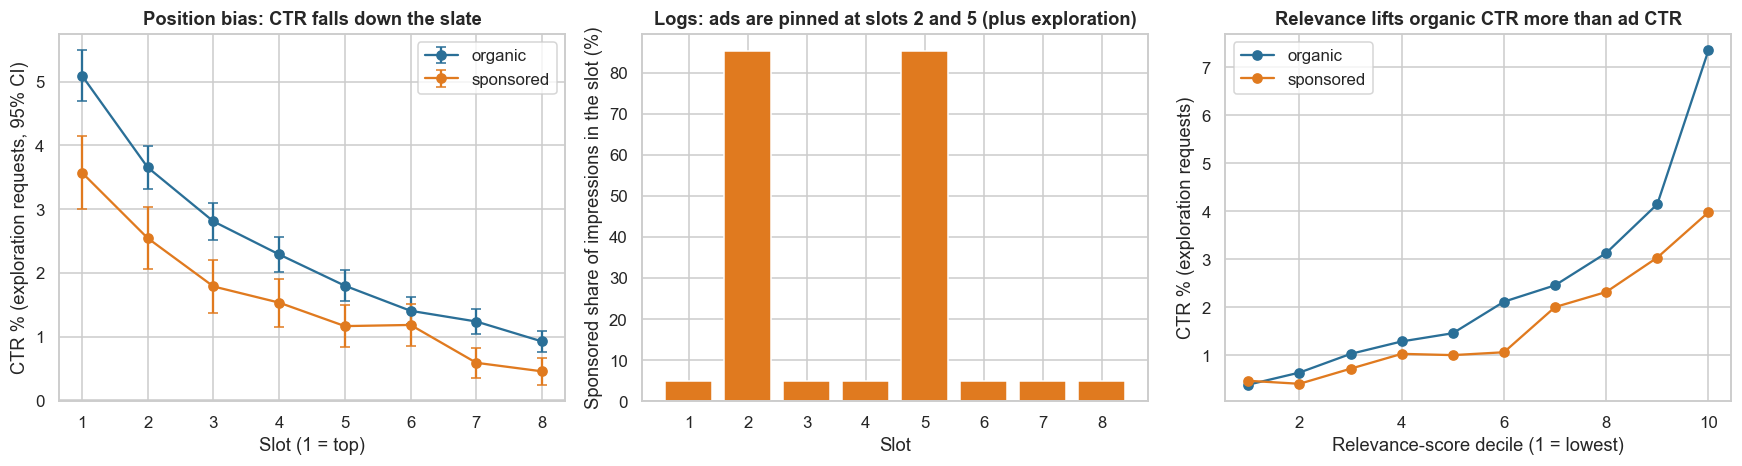

Exploration CTR slot 1 vs slot 8 (all items): 4.72% vs 0.81% (ratio 0.17); ads share of logged impressions in slots 2 and 5: 85%, in other slots: 5%
organic CTR top decile / bottom decile of relevance: 18.9x
sponsored CTR top decile / bottom decile of relevance: 8.5x


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for g_, lab, col in ((0, "organic", "#2a6f97"), (1, "sponsored", "#e07a1f")):
    s_ = ex[ex.is_ads == g_].groupby("slot").click.agg(["mean", "size"]); se = np.sqrt(s_["mean"] * (1 - s_["mean"]) / s_["size"]); axes[0].errorbar(s_.index, s_["mean"] * 100, yerr=1.96 * se * 100, marker="o", label=lab, color=col, capsize=3)
axes[0].set_xlabel("Slot (1 = top)"); axes[0].set_ylabel("CTR % (exploration requests, 95% CI)"); axes[0].set_title("Position bias: CTR falls down the slate"); axes[0].legend()
lg = d.groupby(["slot", "is_ads"]).size().unstack().fillna(0); lg = lg.div(lg.sum(1), axis=0); axes[1].bar(lg.index, lg[1] * 100, color="#e07a1f"); axes[1].set_xlabel("Slot"); axes[1].set_ylabel("Sponsored share of impressions in the slot (%)"); axes[1].set_title("Logs: ads are pinned at slots 2 and 5 (plus exploration)")
for g_, col in ((0, "#2a6f97"), (1, "#e07a1f")):
    e = ex[ex.is_ads == g_].copy(); e["q"] = pd.qcut(e.x_rel, 10, labels=False, duplicates="drop"); r_ = e.groupby("q").click.mean(); axes[2].plot(r_.index + 1, r_.values * 100, marker="o", color=col, label="organic" if g_ == 0 else "sponsored")
axes[2].set_xlabel("Relevance-score decile (1 = lowest)"); axes[2].set_ylabel("CTR % (exploration requests)"); axes[2].set_title("Relevance lifts organic CTR more than ad CTR"); axes[2].legend()
plt.tight_layout(); plt.show()
pe = ex.groupby("slot").click.mean(); print(f"Exploration CTR slot 1 vs slot 8 (all items): {pe.iloc[0]:.2%} vs {pe.iloc[-1]:.2%} (ratio {pe.iloc[-1] / pe.iloc[0]:.2f}); ads share of logged impressions in slots 2 and 5: {lg.loc[[2, 5], 1].mean():.0%}, in other slots: {lg.loc[[1, 3, 4, 6, 7, 8], 1].mean():.0%}")
for g_ in (0, 1):
    e = ex[ex.is_ads == g_].copy(); e["q"] = pd.qcut(e.x_rel, 10, labels=False, duplicates="drop"); r_ = e.groupby("q").click.mean(); print(("organic" if g_ == 0 else "sponsored"), f"CTR top decile / bottom decile of relevance: {r_.iloc[-1] / r_.iloc[0]:.1f}x")

**Takeaway:** position bias is strong. In the exploration bucket CTR falls from **4.72% at slot 1 to 0.81% at slot 8**, a ratio of 0.17. In the logs, sponsored items make up **85% of impressions in slots 2 and 5 but only 5% elsewhere**, so slot and sponsorship are almost the same variable outside the exploration bucket. That is why the models include the slot and are scored at slot 1, and why Request AUC uses exploration requests only. Relevance matters more for organic items: CTR in the top relevance decile is **18.9 times** the bottom decile for organic and **8.5 times** for sponsored. So one set of weights for both populations would be wrong.

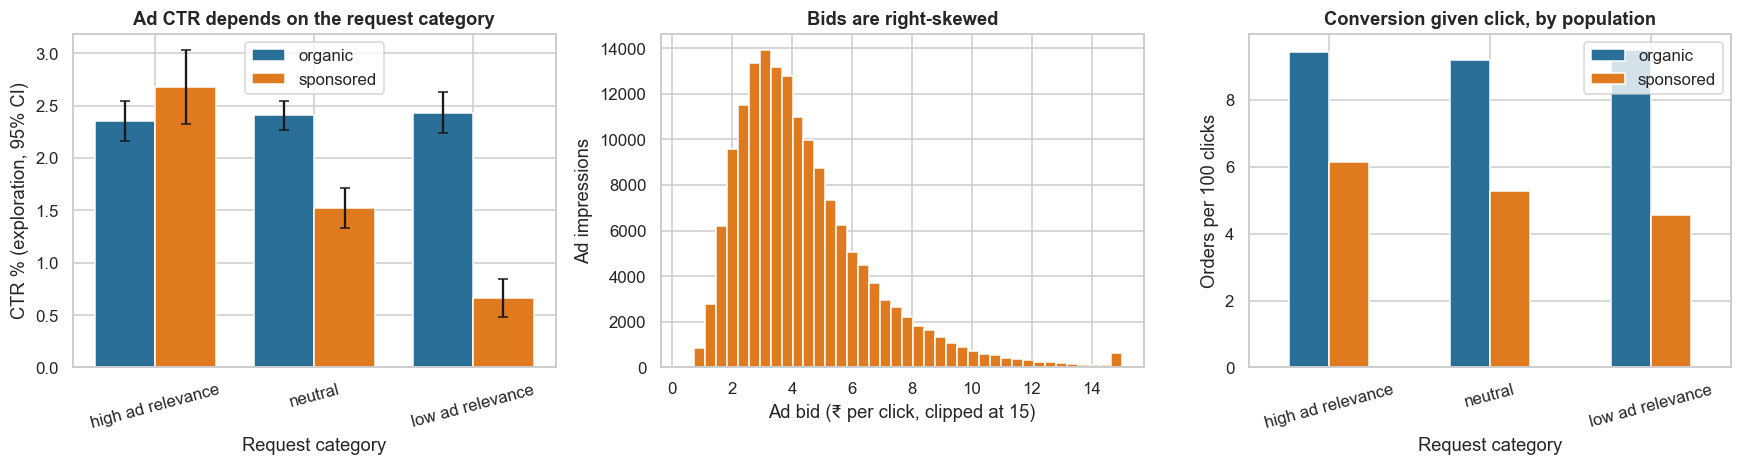

 cat  is_ads  CTR_pct  size
   0       0   2.3550 23991
   0       1   2.6800  7985
   1       0   2.4100 47640
   1       1   1.5250 16128
   2       0   2.4320 23524
   2       1   0.6660  7812
Median ad bid ₹3.89; mean ₹4.40; CVR given click organic 9.3% vs ads 5.5%


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
ct = ex.groupby(["cat", "is_ads"]).click.agg(["mean", "size"]).reset_index(); ct["se"] = np.sqrt(ct["mean"] * (1 - ct["mean"]) / ct["size"]); lab_c = {0: "high ad relevance", 1: "neutral", 2: "low ad relevance"}
w_ = 0.38
for g_, col, nm in ((0, "#2a6f97", "organic"), (1, "#e07a1f", "sponsored")):
    z_ = ct[ct.is_ads == g_]; axes[0].bar(z_.cat + (g_ - 0.5) * w_, z_["mean"] * 100, w_, yerr=1.96 * z_.se * 100, color=col, label=nm, capsize=3)
axes[0].set_xticks([0, 1, 2]); axes[0].set_xticklabels([lab_c[i] for i in range(3)], rotation=15); axes[0].set_xlabel("Request category"); axes[0].set_ylabel("CTR % (exploration, 95% CI)"); axes[0].set_title("Ad CTR depends on the request category"); axes[0].legend()
a_ = d[d.is_ads == 1]; axes[1].hist(np.clip(a_.bid, 0, 15), bins=40, color="#e07a1f"); axes[1].set_xlabel("Ad bid (₹ per click, clipped at 15)"); axes[1].set_ylabel("Ad impressions"); axes[1].set_title("Bids are right-skewed")
cv_ = d[d.click == 1].groupby(["cat", "is_ads"]).order.mean().unstack() * 100; cv_.index = [lab_c[i] for i in cv_.index]; cv_.columns = ["organic", "sponsored"]; cv_.plot.bar(ax=axes[2], color=["#2a6f97", "#e07a1f"]); axes[2].set_xlabel("Request category"); axes[2].set_ylabel("Orders per 100 clicks"); axes[2].set_title("Conversion given click, by population"); axes[2].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()
print(ct.assign(CTR_pct=ct["mean"] * 100).round(3)[["cat", "is_ads", "CTR_pct", "size"]].to_string(index=False)); print(f"Median ad bid ₹{a_.bid.median():.2f}; mean ₹{a_.bid.mean():.2f}; CVR given click organic {d[(d.click == 1) & (d.is_ads == 0)].order.mean():.1%} vs ads {d[(d.click == 1) & (d.is_ads == 1)].order.mean():.1%}")

**Takeaway:** ad CTR depends on the request category, organic CTR does not. In the exploration bucket, ads get **2.68% in high-ad-relevance requests, 1.53% in neutral and 0.67% in low-ad-relevance requests**, against 2.36%, 2.41% and 2.43% for organic items. So an ad beats an organic item only in the first category. This is the pocket-scissors versus smartphone contrast in the case. Bids are right-skewed (median ₹3.89, mean ₹4.40), so a score that adds the bid will let a few high bids dominate. Conversion after a click is lower for ads (5.5% against 9.3%). A model that ignores the flag would treat these two populations as one.

## 7. Statistical Analysis (core section)

### 7.1 Setup: five pCTR models, discrimination (AUC, Request AUC, log loss)

**Protocol:** train on days 0 to 9, test on days 10 to 13 (time split). All models see the **slot** (one-hot) so that position bias is not blamed on the item; at **ranking time the slot is set to 1** for everyone (a position-free score). Features: relevance score, co-browse, popularity, log price ratio, rating, request category.

| # | Model | In one line |
|---|---|---|
| M0 | Organic-features model, no flag | One logistic model on all impressions with no ads indicator and no bid |
| M1 | + isAds flag | M0 plus the flag and the (log) bid |
| M2 | + flag × crosses | M1 plus isAds × each feature, and isAds × category × relevance (the documented 2-way and 3-way crosses, on our 7 base features) |
| M3 | Separate models | One logistic model for organic and one for ads |
| M4 | Gradient boosting | Gradient-boosted trees on the M1 features (interactions learned) |

**Metrics:** AUC overall and within each population; **log loss** (rewards calibration); **Request AUC** = within-request pairwise ordering of clicked above non-clicked items, computed on the **exploration** requests only (random slotting removes position confounding); 95% CIs from a **request-clustered bootstrap** (100 resamples). H1: paired differences versus M1.

#### Code

In [8]:
NUMS = ["x_rel", "cobrowse", "pop", "log_price_ratio", "rating"]; mu_, sd_ = d[NUMS].mean(), d[NUMS].std()
def design(df, kind, slot=None):
    z = ((df[NUMS] - mu_) / sd_).copy().reset_index(drop=True)
    for k in (0, 1, 2): z[f"cat{k}"] = (df.cat.values == k).astype(float)
    sl = df.slot.values if slot is None else np.full(len(df), slot)
    for s_ in range(2, 9): z[f"slot{s_}"] = (sl == s_).astype(float)
    if kind == "M0": return z
    a = df.is_ads.values.astype(float); z["is_ads"] = a; z["bid_log"] = np.log1p(df.bid.values)
    if kind == "M1": return z
    for c in NUMS + ["cat0", "cat1", "cat2"]: z[f"ads_x_{c}"] = a * z[c].values
    for k in (0, 1, 2): z[f"ads_cat{k}_x_rel"] = a * z[f"cat{k}"].values * z["x_rel"].values
    return z
def lr(): return LogisticRegression(C=1.0, max_iter=400)
trm = d.day < 10; D_tr, D_te = d[trm].reset_index(drop=True), d[~trm].reset_index(drop=True)
FIT = {}
for k in ("M0", "M1", "M2"): FIT[k] = lr().fit(design(D_tr, k), D_tr.click)
FIT["M3_org"] = lr().fit(design(D_tr[D_tr.is_ads == 0], "M0"), D_tr[D_tr.is_ads == 0].click); FIT["M3_ads"] = lr().fit(design(D_tr[D_tr.is_ads == 1], "M1"), D_tr[D_tr.is_ads == 1].click)
M4cols = lambda df, slot=None: pd.DataFrame({**{c: df[c].values for c in NUMS}, "cat": df.cat.values, "is_ads": df.is_ads.values, "bid_log": np.log1p(df.bid.values), "slot": df.slot.values if slot is None else np.full(len(df), slot)})
FIT["M4"] = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=100, random_state=SEED).fit(M4cols(D_tr), D_tr.click)
def predict_ctr(kind, df, slot=None):
    if kind in ("M0", "M1", "M2"): return FIT[kind].predict_proba(design(df, kind, slot))[:, 1]
    if kind == "M4": return FIT["M4"].predict_proba(M4cols(df, slot))[:, 1]
    p = np.zeros(len(df)); a = df.is_ads.values == 1
    if (~a).any(): p[~a] = FIT["M3_org"].predict_proba(design(df[~a], "M0", slot))[:, 1]
    if a.any(): p[a] = FIT["M3_ads"].predict_proba(design(df[a], "M1", slot))[:, 1]
    return p
KINDS = ["M0", "M1", "M2", "M3", "M4"]; NAMES = {"M0": "M0 organic features, no flag", "M1": "M1 + isAds flag", "M2": "M2 + flag x crosses", "M3": "M3 separate models", "M4": "M4 gradient boosting"}
P = {k: predict_ctr(k, D_te) for k in KINDS}; yt = D_te.click.values; ad_t = D_te.is_ads.values == 1; nreq_t = len(D_te) // gen.K
def auc(yy, s):
    n1 = yy.sum(); n0 = len(yy) - n1; return np.nan if n1 == 0 or n0 == 0 else (rankdata(s)[yy == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
def ll(yy, p): p = np.clip(p, 1e-9, 1 - 1e-9); return -np.mean(yy * np.log(p) + (1 - yy) * np.log(1 - p))
def metrics_rows(rows):
    out = {}
    for k in KINDS:
        p, yy, a = P[k][rows], yt[rows], ad_t[rows]; out[k] = (auc(yy, p), auc(yy[~a], p[~a]), auc(yy[a], p[a]), ll(yy, p), ll(yy[~a], p[~a]), ll(yy[a], p[a]))
    return out
all_rows = np.arange(len(D_te)); base_m = metrics_rows(all_rows); BR = np.random.default_rng(SEED); NB = 100; bm = []
for _ in range(NB):
    idx = BR.integers(0, nreq_t, nreq_t); rows = (idx[:, None] * gen.K + np.arange(gen.K)).ravel(); bm.append(metrics_rows(rows))
# request AUC on exploration requests, position-free scores (slot = 1)
exr = (D_te.explore.values.reshape(-1, gen.K)[:, 0] == 1); Cm = yt.reshape(-1, gen.K)[exr]; S_free = {k: predict_ctr(k, D_te, slot=1).reshape(-1, gen.K)[exr] for k in KINDS}
def req_auc_parts(S):
    pos, neg = Cm[:, :, None] * (1 - Cm)[:, None, :], None; gt = (S[:, :, None] > S[:, None, :]) + 0.5 * (S[:, :, None] == S[:, None, :]); return (pos * gt).sum((1, 2)), pos.sum((1, 2))
RA = {k: req_auc_parts(S_free[k]) for k in KINDS}; nE = exr.sum(); RB = BR.integers(0, nE, (1000, nE))
rows = []
for j, k in enumerate(KINDS):
    ra = RA[k][0].sum() / RA[k][1].sum(); rb = RA[k][0][RB].sum(1) / RA[k][1][RB].sum(1); b_ = np.array([m[k] for m in bm])
    rows.append((NAMES[k], *base_m[k], ra, np.percentile(b_[:, 0], 2.5), np.percentile(b_[:, 0], 97.5), np.percentile(rb, 2.5), np.percentile(rb, 97.5)))
disc = pd.DataFrame(rows, columns=["model", "AUC", "AUC organic", "AUC ads", "log loss", "log loss organic", "log loss ads", "Request AUC", "AUC low", "AUC high", "ReqAUC low", "ReqAUC high"]).set_index("model")
print(f"Test: {nreq_t:,} requests, {len(D_te):,} impressions, clicks {yt.sum():,} (ads {yt[ad_t].sum():,}); exploration requests {nE:,} with at least one click {int((Cm.sum(1) > 0).sum()):,}")
disc.round(4)

Test: 22,749 requests, 181,992 impressions, clicks 6,638 (ads 966); exploration requests 4,464 with at least one click 684


,AUC,AUC organic,AUC ads,log loss,log loss organic,log loss ads,Request AUC,AUC low,AUC high,ReqAUC low,ReqAUC high
model,,,,,,,,,,,
"M0 organic features, no flag",0.7980,0.8070,0.7158,0.1328,0.1448,0.0967,0.7331,0.7932,0.8026,0.7123,0.7534
M1 + isAds flag,0.7979,0.8069,0.7153,0.1328,0.1448,0.0967,0.7337,0.7933,0.8025,0.7132,0.7543
M2 + flag x crosses,0.7993,0.8071,0.7215,0.1325,0.1448,0.0959,0.7392,0.7946,0.8042,0.7187,0.7584
M3 separate models,0.7994,0.8071,0.7215,0.1325,0.1448,0.0959,0.7388,0.7946,0.8043,0.7176,0.7584
M4 gradient boosting,0.7972,0.8062,0.7124,0.1329,0.1451,0.0965,0.7327,0.7922,0.8020,0.7114,0.7532


In [9]:
rows = []; ref = "M1"; pv = []
for k in KINDS:
    if k == ref: continue
    b_ = np.array([[m[k][i] - m[ref][i] for i in range(6)] for m in bm]); rb = RA[k][0][RB].sum(1) / RA[k][1][RB].sum(1) - RA[ref][0][RB].sum(1) / RA[ref][1][RB].sum(1); d0 = base_m[k][5] - base_m[ref][5]
    p_ll = max(2 * min((b_[:, 5] >= 0).mean(), (b_[:, 5] <= 0).mean()), 1 / NB); pv.append(p_ll)
    rows.append((NAMES[k], base_m[k][0] - base_m[ref][0], np.percentile(b_[:, 0], 2.5), np.percentile(b_[:, 0], 97.5), d0, np.percentile(b_[:, 5], 2.5), np.percentile(b_[:, 5], 97.5), p_ll, RA[k][0].sum() / RA[k][1].sum() - RA[ref][0].sum() / RA[ref][1].sum(), np.percentile(rb, 2.5), np.percentile(rb, 97.5)))
dif = pd.DataFrame(rows, columns=[f"vs {NAMES[ref]}", "ΔAUC", "low", "high", "Δlog loss ads", "low ", "high ", "bootstrap p", "ΔRequest AUC", "low  ", "high  "]).set_index(f"vs {NAMES[ref]}"); dif["p_holm (log loss ads)"] = multipletests(dif["bootstrap p"], method="holm")[1]
dif.round(4)

,ΔAUC,low,high,Δlog loss ads,low,high,bootstrap p,ΔRequest AUC,low,high,p_holm (log loss ads)
vs M1 + isAds flag,,,,,,,,,,,
"M0 organic features, no flag",0.0001,-0.0001,0.0002,-0.0000,-0.0001,0.0000,0.2200,-0.0006,-0.0027,0.0017,0.4400
M2 + flag x crosses,0.0015,0.0008,0.0023,-0.0008,-0.0012,-0.0005,0.0100,0.0055,0.0004,0.0110,0.0400
M3 separate models,0.0015,0.0009,0.0023,-0.0008,-0.0012,-0.0005,0.0100,0.0051,-0.0000,0.0103,0.0400
M4 gradient boosting,-0.0006,-0.0017,0.0004,-0.0002,-0.0006,0.0001,0.2600,-0.0010,-0.0099,0.0079,0.4400


**(c)/(f) Observation:** **(c)** Adding the flag does little by itself: M1 and M0 are indistinguishable (ΔAUC 0.0001, Holm p = 0.44 for ad log loss). **Crosses help a little, and only for ads:** M2 raises overall AUC by **0.0015** (CI 0.0008 to 0.0023) and ad AUC from 0.7153 to **0.7215**, lowers ad log loss by **0.0008** (CI 0.0005 to 0.0012; Holm p = 0.04) and raises Request AUC by **0.0055** (CI 0.0004 to 0.0110). Separate models (M3) do the same (Request AUC +0.0051, CI -0.0000 to 0.0103). Gradient boosting is not better than the logistic model (AUC 0.7972, ad AUC 0.7124). Organic AUC is about 0.807 in every model; ad AUC is about 0.72. **(f)** H1 is rejected, narrowly and with tiny effect sizes. The bootstrap uses 100 resamples, so the smallest possible p is 0.01 and the Holm p of 0.04 is close to the line. The gain is concentrated in the ad population, as the company describes (a larger lift for ads, organic about unchanged), but we cannot judge the size of their lift because their values are not given.

### 7.2 Calibration across populations: ads vs organic

**(a) Why?** The ranker compares an ad's pCTR with an organic item's pCTR, so each population's predictions must be calibrated on its own. For each model and population we fit (i) a **calibration-in-the-large** model (logistic regression of the click on an offset of logit(p); the intercept is the log of the over/under-prediction, H0: 0) and (ii) a **calibration slope** (logistic regression of the click on logit(p); H0: slope = 1), both with request-clustered standard errors. We also report the ratio of the actual to the predicted click rate on the **exploration** requests alone, and the **expected calibration error** (10 equal-frequency bins). Holm across the 10 intercept tests.

#### Code

In [10]:
def calib(p, yy, grp):
    p = np.clip(p, 1e-6, 1 - 1e-6); lg_ = np.log(p / (1 - p)); f1 = sm.GLM(yy, sm.add_constant(lg_), family=sm.families.Binomial()).fit(cov_type="cluster", cov_kwds={"groups": grp})
    f2 = sm.GLM(yy, np.ones(len(yy)), family=sm.families.Binomial(), offset=lg_).fit(cov_type="cluster", cov_kwds={"groups": grp})
    q = pd.qcut(p, 10, labels=False, duplicates="drop"); g = pd.DataFrame({"p": p, "y": yy, "q": q}).groupby("q").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size")); ece = (g.n * (g.p - g.y).abs()).sum() / g.n.sum()
    return f2.params[0], f2.bse[0], f2.pvalues[0], f1.params[1], f1.bse[1], ece
rows = []; grp_t = D_te.request_id.values; ex_t = D_te.explore.values == 1
for k in KINDS:
    for gname, m_ in (("organic", ~ad_t), ("ads", ad_t)):
        ci, cse, cp, sl_, sse, ece = calib(P[k][m_], yt[m_], grp_t[m_]); me = m_ & ex_t
        rows.append((NAMES[k], gname, P[k][m_].mean(), yt[m_].mean(), yt[m_].sum() / P[k][m_].sum(), ci, ci - 1.96 * cse, ci + 1.96 * cse, cp, sl_, sl_ - 1.96 * sse, sl_ + 1.96 * sse, 2 * stats.norm.sf(abs(sl_ - 1) / sse), ece, yt[me].sum() / P[k][me].sum()))
cal = pd.DataFrame(rows, columns=["model", "population", "mean predicted", "mean actual", "actual / predicted", "intercept (CITL)", "int low", "int high", "p (intercept)", "slope", "slope low", "slope high", "p (slope = 1)", "ECE", "exploration actual / predicted"]).set_index(["model", "population"])
cal["p_holm (intercept)"] = multipletests(cal["p (intercept)"], method="holm")[1]
cal.round(4)

mean predicted  mean actual  actual / predicted  intercept (CITL)  int low  int high  p (intercept)  slope  slope low  \
model                        population                                                                                                                          
M0 organic features, no flag organic             0.0415       0.0416              1.0024            0.0027  -0.0248    0.0303         0.8458 1.0304     1.0053   
                             ads                 0.0209       0.0212              1.0154            0.0160  -0.0493    0.0814         0.6307 0.7824     0.7170   
M1 + isAds flag              organic             0.0413       0.0416              1.0053            0.0060  -0.0215    0.0336         0.6687 1.0284     1.0032   
                             ads                 0.0210       0.0212              1.0098            0.0103  -0.0551    0.0756         0.7577 0.7820     0.7167   
M2 + flag x crosses          organic             0.0414       0.0416              1.0043            0.0048  -0.0229    0.0326         0.7327 0.9979     0.9737   
                             ads                 0.0211       0.0212              1.0060            0.0063  -0.0582    0.0707         0.8490 0.9962     0.9135   
M3 separate models           organic             0.0413       0.0416              1.0062            0.0070  -0.0207    0.0348         0.6197 0.9974     0.9732   
                             ads                 0.0211       0.0212              1.0065            0.0068  -0.0577    0.0712         0.8367 0.9909     0.9084   
M4 gradient boosting         organic             0.0413       0.0416              1.0055            0.0062  -0.0215    0.0340         0.6593 0.9973     0.9734   
                             ads                 0.0211       0.0212              1.0056            0.0058  -0.0590    0.0706         0.8602 0.8707     0.7974   

                                         slope high  p (slope = 1)    ECE  exploration actual / predicted  p_holm (intercept)  
model                        population                                                                                        
M0 organic features, no flag organic         1.0556         0.0175 0.0012                          0.9214              1.0000  
                             ads             0.8477         0.0000 0.0037                          1.0752              1.0000  
M1 + isAds flag              organic         1.0535         0.0270 0.0013                          0.9369              1.0000  
                             ads             0.8473         0.0000 0.0037                          1.0525              1.0000  
M2 + flag x crosses          organic         1.0221         0.8646 0.0008                          0.9471              1.0000  
                             ads             1.0789         0.9276 0.0014                          1.0237              1.0000  
M3 separate models           organic         1.0217         0.8362 0.0007                          0.9536              1.0000  
                             ads             1.0734         0.8286 0.0017                          0.9471              1.0000  
M4 gradient boosting         organic         1.0212         0.8237 0.0012                          0.9697              1.0000  
                             ads             0.9440         0.0005 0.0025                          1.0017              1.0000

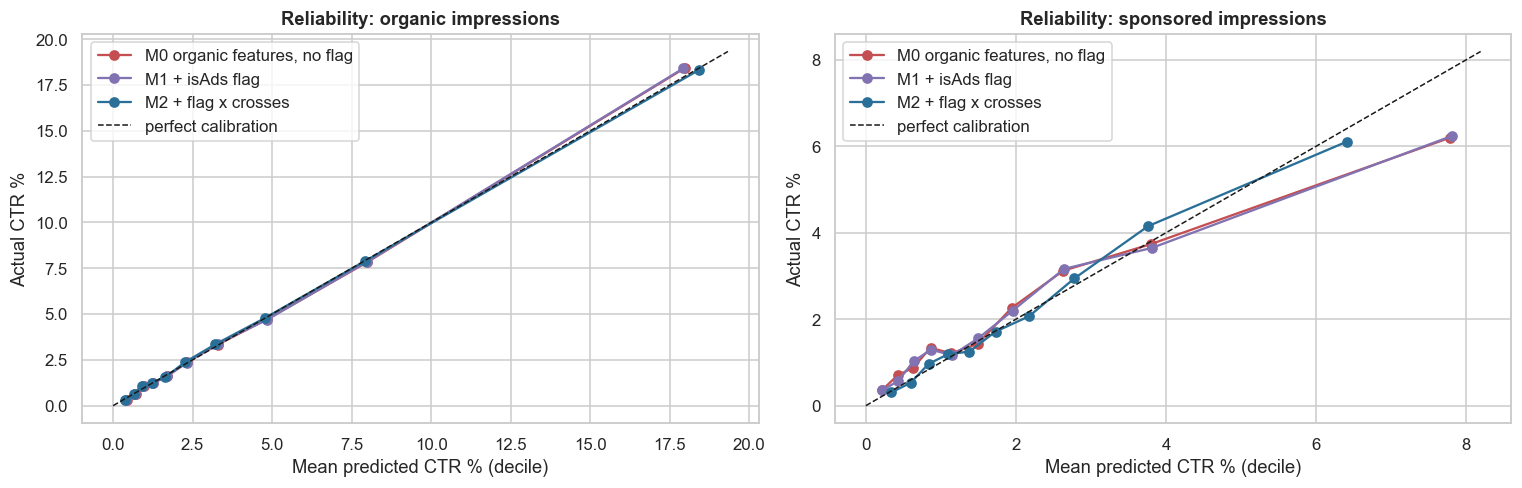

Actual / predicted click rate by population:
population                      ads  organic
model                                       
M0 organic features, no flag 1.0150   1.0020
M1 + isAds flag              1.0100   1.0050
M2 + flag x crosses          1.0060   1.0040
M3 separate models           1.0070   1.0060
M4 gradient boosting         1.0060   1.0050


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, (gname, m_) in zip(axes, (("organic", ~ad_t), ("sponsored", ad_t))):
    for k, col in (("M0", "#c44e52"), ("M1", "#8172b2"), ("M2", "#2a6f97")):
        p = P[k][m_]; q = pd.qcut(p, 10, labels=False, duplicates="drop"); g = pd.DataFrame({"p": p, "y": yt[m_], "q": q}).groupby("q").mean(); ax.plot(g.p * 100, g.y * 100, marker="o", label=NAMES[k], color=col)
    lim = max(ax.get_xlim()[1], ax.get_ylim()[1]); ax.plot([0, lim], [0, lim], "k--", lw=1, label="perfect calibration"); ax.set_xlabel("Mean predicted CTR % (decile)"); ax.set_ylabel("Actual CTR %"); ax.set_title(f"Reliability: {gname} impressions"); ax.legend()
plt.tight_layout(); plt.show()
cs = cal["actual / predicted"].unstack(); print("Actual / predicted click rate by population:"); print(cs.round(3).to_string())

**Takeaway:** **(c)** On average every model is calibrated: actual over predicted is between **1.002 and 1.015** for both populations and no intercept test is rejected (Holm p = 1.0). The ad intercept intervals are wide (about ±0.06 on the log scale), so this test has limited power. The **slope** shows the problem. For ads, the models without crosses give a slope of **0.78** (CI 0.72 to 0.85; M0 and M1), meaning ad predictions are too spread out (the best-looking ads are over-predicted). Gradient boosting gives 0.87 (p = 0.0005). With crosses (M2) the slope is **0.996** (0.91 to 1.08) and separate models give 0.991 (0.91 to 1.07). Expected calibration error for ads falls from 0.0037 to 0.0014 (M2). On the exploration bucket alone, actual over predicted for ads is 1.075 (M0), 1.05 (M1), 1.02 (M2), 0.95 (M3) and 1.00 (M4); for organic items it is 0.92 to 0.97, so organic clicks are slightly over-predicted there. **(f)** H2 is rejected for the ad slope in M0, M1 and M4 (p < 0.001, not Holm-adjusted) and not rejected for M2 and M3. The organic slopes of M0 and M1 (1.03; p = 0.018 and 0.027, unadjusted) are statistically detectable and practically negligible.

### 7.3 pCVR: does the same logic hold for conversion, with far fewer events?

**(a) Why?** The score uses pCTR × pCVR. Conversions given a click are rare (especially for ads), so the CVR model is the noisier half. We fit three logistic CVR models on clicked impressions (days 0 to 9) and test on days 10 to 13: C0 no flag, C1 + flag and bid, C2 + flag × crosses. Metrics: AUC, log loss and the ratio of actual to predicted conversion by population (cluster-robust CI). H0: each population is calibrated (ratio = 1).

#### Code

In [12]:
def design_cv(df, kind):
    z = ((df[NUMS] - mu_) / sd_).copy().reset_index(drop=True)
    for k in (0, 1, 2): z[f"cat{k}"] = (df.cat.values == k).astype(float)
    if kind == "C0": return z
    a = df.is_ads.values.astype(float); z["is_ads"] = a; z["bid_log"] = np.log1p(df.bid.values)
    if kind == "C1": return z
    for c in NUMS + ["cat0", "cat1", "cat2"]: z[f"ads_x_{c}"] = a * z[c].values
    return z
CT_tr, CT_te = D_tr[D_tr.click == 1].reset_index(drop=True), D_te[D_te.click == 1].reset_index(drop=True); CFIT = {k: LogisticRegression(C=1.0, max_iter=400).fit(design_cv(CT_tr, k), CT_tr.order) for k in ("C0", "C1", "C2")}
yo = CT_te.order.values; ad_c = CT_te.is_ads.values == 1; PC_ = {k: CFIT[k].predict_proba(design_cv(CT_te, k))[:, 1] for k in CFIT}; rows = []
print(f"Training clicks {len(CT_tr):,} (orders {int(CT_tr.order.sum()):,}; ads orders {int(CT_tr[CT_tr.is_ads == 1].order.sum()):,}) | test clicks {len(CT_te):,} (orders {int(yo.sum()):,}; ads orders {int(yo[ad_c].sum()):,})")
bs_ = np.random.default_rng(SEED); BX = bs_.integers(0, len(CT_te), (300, len(CT_te)))
for k, nm in (("C0", "C0 no flag"), ("C1", "C1 + isAds flag"), ("C2", "C2 + flag x crosses")):
    p = PC_[k]; ab = np.array([auc(yo[ix], p[ix]) for ix in BX]); row = [nm, auc(yo, p), np.percentile(ab, 2.5), np.percentile(ab, 97.5), ll(yo, p)]
    for m_ in (~ad_c, ad_c):
        p_ = np.clip(p[m_], 1e-6, 1 - 1e-6); lg_ = np.log(p_ / (1 - p_)); f = sm.GLM(yo[m_], np.ones(m_.sum()), family=sm.families.Binomial(), offset=lg_).fit(cov_type="cluster", cov_kwds={"groups": CT_te.request_id.values[m_]}); row += [yo[m_].sum() / p_.sum(), np.exp(f.params[0] - 1.96 * f.bse[0]), np.exp(f.params[0] + 1.96 * f.bse[0]), f.pvalues[0]]
    rows.append(row)
cvr = pd.DataFrame(rows, columns=["model", "AUC", "AUC low", "AUC high", "log loss", "organic actual/pred", "org low", "org high", "org p", "ads actual/pred", "ads low", "ads high", "ads p"]).set_index("model")
cvr.round(4)

Training clicks 16,570 (orders 1,453; ads orders 135) | test clicks 6,638 (orders 584; ads orders 52)


,AUC,AUC low,AUC high,log loss,organic actual/pred,org low,org high,org p,ads actual/pred,ads low,ads high,ads p
model,,,,,,,,,,,,
C0 no flag,0.6297,0.6055,0.6530,0.2896,1.0162,0.9307,1.1137,0.6953,0.8548,0.6380,1.1192,0.2401
C1 + isAds flag,0.6307,0.6064,0.6536,0.2895,1.0013,0.9155,1.0954,0.9756,0.9736,0.7341,1.2866,0.8418
C2 + flag x crosses,0.6292,0.6043,0.6524,0.2896,1.0015,0.9155,1.0959,0.9714,0.9578,0.7225,1.2631,0.7483


**Observation:** conversion is hard to predict and the flag does not help. AUC is **0.630** (CI 0.606 to 0.653) for C0, **0.631** for C1 and **0.629** for C2, all with overlapping intervals. The test set has 6,638 clicks but only **584 orders, 52 of them from ads** (training: 1,453 orders, 135 from ads). Actual over predicted for ads is 0.85 (CI 0.64 to 1.12), 0.97 (0.73 to 1.29) and 0.96 (0.72 to 1.26) for C0, C1 and C2; none is significantly different from 1 (p = 0.24, 0.84, 0.75). Organic ratios are 1.00 to 1.02. So there is no evidence of miscalibration, but with 52 ad orders we could not detect an error smaller than about 25% to 30%. The CVR model is the noisy half of the score. We use C2 in the ranking comparison as the documented design, not because it was shown to be better.

### 7.4 Does unified ranking beat pinned slots? A twin comparison on the same candidate sets

**(a) Why?** Offline AUC cannot say what happens when the **ranking policy** changes, because the logs only contain the items the old policy showed. In the digital twin we generate fresh candidate sets (12 organic + 4 sponsored), rank them with each policy and compute the **expected** outcome under the hidden true click and order model (position bias included). Every policy sees the **same requests**, so differences are paired and tested with a **bootstrap over requests** (1,000 resamples); Holm across the 12 tests on the two primary metrics.

**Scoring rule** (our assumption; the company's exact formula is not disclosed): value per impression = pCTR × (a + b × pCVR) for organic items, with a = ₹0.30 per click and b = ₹60 per order; sponsored items add the bid: pCTR × (λ × bid + a + b × pCVR). Here **λ = 1** (bid at face value). Policies: **pinned** (legacy: organic by relevance, two ads at slots 2 and 5), unified with each of the five pCTR models (pCVR from C2), and an **oracle** unified policy using the true probabilities.

#### Code

In [13]:
EXAM = np.array(gen.EXAM); A_CLK, B_ORD = 0.30, 60.0; NR_T, NR_E = 20_000, 30_000; ss = np.random.SeedSequence(SEED + 17).spawn(3)
def make_set(n, seed_seq):
    r = np.random.default_rng(seed_seq); c = gen.make_candidates(n, r); c["bid_log"] = np.log1p(c.bid); c["slot"] = 1
    S = {k: c[k].values.reshape(n, 16) for k in ("is_ads", "bid", "_p_ctr_attr", "_p_cvr")}; S["pinned"] = gen.legacy_slate(c, np.random.default_rng(seed_seq.spawn(1)[0]))
    S["pc"] = {k: predict_ctr(k, c, slot=1).reshape(n, 16) for k in KINDS}; S["cv"] = {k: CFIT[k].predict_proba(design_cv(c, k))[:, 1].reshape(n, 16) for k in CFIT}; return c, S
cand_tune, S_tune = make_set(NR_T, ss[0]); cand_test, S_test = make_set(NR_E, ss[1])
def slate_by_score(S, pc, cv, lam):
    val = pc * (np.where(S["is_ads"] == 1, lam * S["bid"], 0.0) + A_CLK + B_ORD * cv); return np.argsort(-val, axis=1)[:, :gen.K]
def outcomes(S, slate):
    tk = lambda a: np.take_along_axis(a, slate, 1); pa = tk(S["_p_ctr_attr"]) * EXAM; cvt = tk(S["_p_cvr"]); ad = tk(S["is_ads"]); bid = tk(S["bid"]); od = pa * cvt
    return {"organic orders": (od * (1 - ad)).sum(1), "ad revenue": (pa * bid * ad).sum(1), "ad orders": (od * ad).sum(1), "sponsored share": ad.mean(1), "clicks": pa.sum(1)}
def pol(S, kind, lam=1.0):
    if kind == "pinned": return S["pinned"]
    if kind == "oracle": return slate_by_score(S, S["_p_ctr_attr"], S["_p_cvr"], lam)
    return slate_by_score(S, S["pc"][kind], S["cv"]["C2"], lam)
BQ = np.random.default_rng(SEED).integers(0, NR_E, (1000, NR_E))
def lift_ci(o, o0, key):
    a, b = o[key], o0[key]; l_ = (a.mean() - b.mean()) / b.mean(); d_ = a - b; mb = d_[BQ].mean(1); rel = mb / b[BQ].mean(1); p_ = max(2 * min((mb <= 0).mean(), (mb >= 0).mean()), 1 / 1000); return l_, np.percentile(rel, 2.5), np.percentile(rel, 97.5), p_
O0 = outcomes(S_test, pol(S_test, "pinned")); POL = {"unified, " + NAMES[k]: k for k in KINDS}; POL["unified, oracle (true probabilities)"] = "oracle"; rows = []; OC = {}
for nm, k in POL.items():
    o = outcomes(S_test, pol(S_test, k, 1.0)); OC[nm] = o; lo_, a1, b1, p1 = lift_ci(o, O0, "organic orders"); lr_, a2, b2, p2 = lift_ci(o, O0, "ad revenue")
    rows.append((nm, 1000 * o["organic orders"].mean(), lo_, a1, b1, p1, 1000 * o["ad revenue"].mean(), lr_, a2, b2, p2, o["sponsored share"].mean()))
uni = pd.DataFrame(rows, columns=["policy", "organic orders / 1,000 req", "lift", "low", "high", "p", "ad revenue ₹ / 1,000 req", "lift ", "low ", "high ", "p ", "sponsored share of slots"]).set_index("policy")
pa_ = uni["p"].values; pb_ = uni["p "].values; hp = multipletests(np.r_[pa_, pb_], method="holm")[1]; uni["p_holm (orders)"] = hp[: len(pa_)]; uni["p_holm (revenue)"] = hp[len(pa_):]
print(f"Pinned (legacy): organic orders {1000 * O0['organic orders'].mean():.2f} / 1,000 requests; ad revenue ₹{1000 * O0['ad revenue'].mean():.1f} / 1,000 requests; sponsored share {O0['sponsored share'].mean():.1%}; {NR_E:,} test requests")
uni.round(4)

Pinned (legacy): organic orders 26.55 / 1,000 requests; ad revenue ₹213.1 / 1,000 requests; sponsored share 25.0%; 30,000 test requests


,"organic orders / 1,000 req",lift,low,high,p,"ad revenue ₹ / 1,000 req",lift,low,high,p,sponsored share of slots,p_holm (orders),p_holm (revenue)
policy,,,,,,,,,,,,,
"unified, M0 organic features, no flag",30.4198,0.1457,0.1430,0.1482,0.0010,213.8207,0.0034,-0.0028,0.0094,0.2960,0.2479,0.0120,0.2960
"unified, M1 + isAds flag",30.2460,0.1392,0.1364,0.1417,0.0010,221.6092,0.0400,0.0338,0.0459,0.0010,0.2529,0.0120,0.0120
"unified, M2 + flag x crosses",30.3161,0.1418,0.1392,0.1442,0.0010,225.2233,0.0569,0.0510,0.0629,0.0010,0.2995,0.0120,0.0120
"unified, M3 separate models",30.4053,0.1451,0.1425,0.1476,0.0010,221.5513,0.0397,0.0336,0.0454,0.0010,0.2985,0.0120,0.0120
"unified, M4 gradient boosting",30.1564,0.1358,0.1331,0.1382,0.0010,220.6114,0.0353,0.0291,0.0408,0.0010,0.2820,0.0120,0.0120
"unified, oracle (true probabilities)",32.1764,0.2119,0.2087,0.2146,0.0010,236.2618,0.1087,0.1031,0.1149,0.0010,0.3116,0.0120,0.0120


**(c)/(f) Observation:** **(c)** Against pinned slots (26.55 organic orders and ₹213.1 ad revenue per 1,000 requests, sponsored share 25.0%), unified ranking with lambda = 1 raises organic orders for every model, by **+13.6% to +14.6%**. Ad revenue depends on the model: **+5.7%** for M2 (CI 5.1% to 6.3%), +4.0% for M1, +4.0% for M3 and +3.5% for M4, but only **+0.3% for M0** (CI -0.3% to 0.9%; Holm p = 0.30), which does not know which items are ads. The oracle with true probabilities reaches **+21.2% organic orders and +10.9% revenue**, so M2 captures about two-thirds of the oracle gain in organic orders and about half in revenue. **(f)** H3 is rejected for organic orders in all models (Holm p = 0.012, the floor with 1,000 resamples) and for revenue in all models except M0. Sponsored share of slots is 30.0% for M2 and 24.8% for M0. Much of the organic gain probably comes from showing items by predicted click value instead of by relevance with fixed ad slots; we did not separate the two. The twin knows the true probabilities, so these are effects of the policy, not estimates from logs.

### 7.5 Choosing the weights: the Pareto frontier and a "do no harm" rule

**(a) Why?** The documented design picks weights by offline simulation as a **multi-objective** problem. The bid weight λ moves the policy along a frontier between organic orders and ad revenue. We sweep λ on a **tuning set** of 20,000 fresh requests for the flag + crosses model (M2) and for the organic-features model (M0), choose the λ that **maximises ad revenue subject to organic orders not falling below the pinned policy** (fall back to λ = 0 if none qualifies), and evaluate that λ once on the **separate test set** with paired bootstrap CIs and Holm across the two primary metrics. H4: the lift in revenue is flat in λ.

#### Code

In [14]:
LAMS = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 5.0]; O0t = outcomes(S_tune, pol(S_tune, "pinned")); fr = []
for k in ("M2", "M0"):
    for lam in LAMS:
        o = outcomes(S_tune, pol(S_tune, k, lam)); fr.append((k, lam, o["organic orders"].mean() / O0t["organic orders"].mean() - 1, o["ad revenue"].mean() / O0t["ad revenue"].mean() - 1, o["sponsored share"].mean()))
fr = pd.DataFrame(fr, columns=["model", "lambda", "organic orders lift", "ad revenue lift", "sponsored share"])
STAR = {}
for k in ("M2", "M0"):
    f_ = fr[(fr.model == k) & (fr["organic orders lift"] >= 0)]; STAR[k] = float(f_.loc[f_["ad revenue lift"].idxmax(), "lambda"]) if len(f_) else 0.0
rows = []
for k in ("M2", "M0"):
    o = outcomes(S_test, pol(S_test, k, STAR[k])); OC[f"tuned {k}"] = o; lo_, a1, b1, p1 = lift_ci(o, O0, "organic orders"); lr_, a2, b2, p2 = lift_ci(o, O0, "ad revenue"); hp = multipletests([p1, p2], method="holm")[1]
    rows.append((f"{NAMES[k]} at tuned lambda = {STAR[k]}", lo_, a1, b1, hp[0], lr_, a2, b2, hp[1], o["sponsored share"].mean(), (o["organic orders"].sum() + o["ad orders"].sum()) / (O0["organic orders"].sum() + O0["ad orders"].sum()) - 1))
tun = pd.DataFrame(rows, columns=["policy (test set)", "organic orders lift", "low", "high", "p_holm", "ad revenue lift", "low ", "high ", "p_holm ", "sponsored share", "total orders lift"]).set_index("policy (test set)")
print(f"Chosen lambda on the tuning set: M2 = {STAR['M2']}, M0 = {STAR['M0']}"); display(fr.round(4)); tun.round(4)

Chosen lambda on the tuning set: M2 = 3.0, M0 = 3.0


,model,lambda,organic orders lift,ad revenue lift,sponsored share
0,M2,0.0000,0.2107,-0.4193,0.1825
1,M2,0.2500,0.1950,-0.2606,0.2216
2,M2,0.5000,0.1784,-0.1355,0.2536
3,M2,1.0000,0.1430,0.0581,0.3007
4,M2,1.5000,0.1088,0.1927,0.3357
5,M2,2.0000,0.0762,0.2954,0.3617
6,M2,3.0000,0.0169,0.4390,0.3976
7,M2,5.0000,-0.0788,0.5987,0.4381
8,M0,0.0000,0.2099,-0.4398,0.1490
9,M0,0.2500,0.1952,-0.2963,0.1801


,organic orders lift,low,high,p_holm,ad revenue lift,low,high,p_holm,sponsored share,total orders lift
policy (test set),,,,,,,,,,
M2 + flag x crosses at tuned lambda = 3.0,0.0147,0.0119,0.0177,0.0020,0.4407,0.4358,0.4455,0.0020,0.3962,0.0670
"M0 organic features, no flag at tuned lambda = 3.0",0.0318,0.0288,0.0347,0.0020,0.3759,0.3710,0.3809,0.0020,0.3414,0.0811


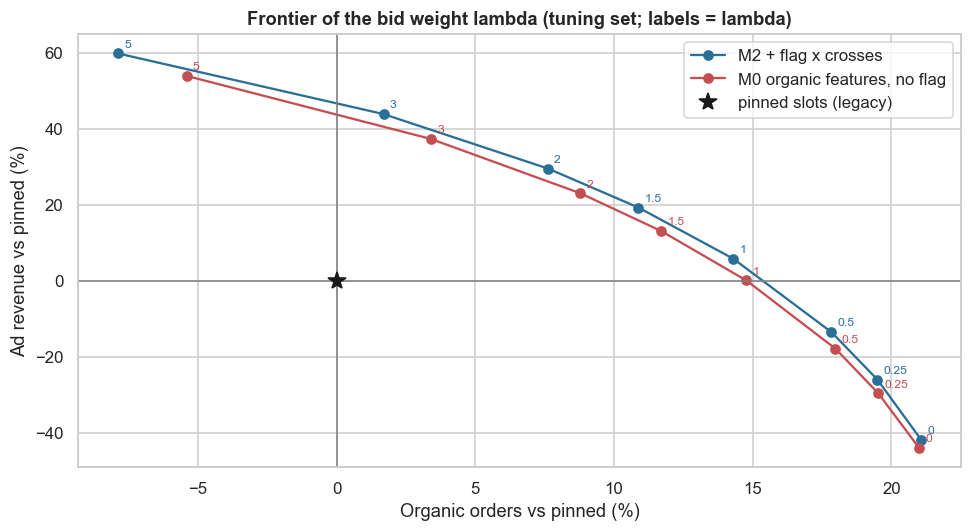

Best point with organic orders not below pinned: {'M2': (3.0, 43.9), 'M0': (3.0, 37.35)}


In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
for k, col in (("M2", "#2a6f97"), ("M0", "#c44e52")):
    f_ = fr[fr.model == k]; ax.plot(f_["organic orders lift"] * 100, f_["ad revenue lift"] * 100, marker="o", color=col, label=NAMES[k])
    for _, r_ in f_.iterrows(): ax.annotate(f"{r_['lambda']:g}", (r_["organic orders lift"] * 100, r_["ad revenue lift"] * 100), textcoords="offset points", xytext=(4, 4), fontsize=8, color=col)
ax.axhline(0, color="grey", lw=1); ax.axvline(0, color="grey", lw=1); ax.plot([0], [0], "k*", ms=12, label="pinned slots (legacy)"); ax.set_xlabel("Organic orders vs pinned (%)"); ax.set_ylabel("Ad revenue vs pinned (%)"); ax.set_title("Frontier of the bid weight lambda (tuning set; labels = lambda)"); ax.legend()
plt.tight_layout(); plt.show()
print("Best point with organic orders not below pinned:", {k: (STAR[k], round(float(fr[(fr.model == k) & (fr['lambda'] == STAR[k])]['ad revenue lift'].iloc[0]) * 100, 2)) for k in STAR})

**Takeaway:** the frontier is steep. On the tuning set for M2, lambda = 0 gives +21.1% organic orders but **-41.9%** ad revenue (sponsored share 18.3%), lambda = 1 gives +14.3% and +5.8% (30.1%), and lambda = 3 gives **+1.7% and +43.9%** (39.8%). Lambda = 5 breaks the rule (organic orders -7.9%). Going from lambda = 1 to 3 buys about 38 points of revenue for about 13 points of organic lift. The rule picks **lambda = 3 for both M2 and M0**. On the separate test set, M2 gives **+1.5% organic orders** (CI 1.2% to 1.8%) and **+44.1% ad revenue** (43.6% to 44.5%), and total orders (organic plus ad) rise by 6.7%. M0 gives **+3.2% and +37.6%**, and total orders +8.1%. So the flag-and-crosses model buys about 6.5 points more revenue but about 1.7 points fewer organic orders at its optimum; the winner depends on the weight put on each. H4 is rejected: revenue lift ranges from -42% to +60% across lambda. The constraint held out of sample, but the sponsored share rises to about 40% of slots, and the model of shopper reaction to more ads is missing here (no fatigue, no long-term effect). Treat lambda = 3 as the upper end, not the launch value.

### 7.6 Failure modes: the 0.5 default and the circuit breaker

**(a) Why?** The case warns that a default score of 0.5 for missing predictions could flood the page with ads. We simulate a scoring outage for a share *f* of the sponsored candidates (f = 0, 1%, 5%, 10%, 25%) in the tuned M2 policy, where a failed ad gets pCTR = **0.5**. Two guards are compared: (i) a **safe default**, the population's mean pCTR; (ii) a **circuit breaker** that reverts a request to the pinned slate if all four sponsored candidates enter the slate (a sponsored-share cap of 4 in 8 slots, our assumption). H5: the failure raises the sponsored share and lowers organic orders; the guards restore them.

#### Code

In [16]:
rf = np.random.default_rng(SEED + 5); Sx = S_test; lamM2 = STAR["M2"]; base_pc = Sx["pc"]["M2"]; safe = base_pc[Sx["is_ads"] == 1].mean(); rows = []
for f in (0.0, 0.01, 0.05, 0.10, 0.25):
    fail = (Sx["is_ads"] == 1) & (rf.random(Sx["is_ads"].shape) < f)
    for mode in ("default 0.5", "safe default (mean ad pCTR)", "default 0.5 + circuit breaker"):
        pc_ = np.where(fail, safe if mode.startswith("safe") else 0.5, base_pc); slate = slate_by_score(Sx, pc_, Sx["cv"]["C2"], lamM2); tripped = np.zeros(len(slate), bool)
        if "breaker" in mode:
            tripped = np.take_along_axis(Sx["is_ads"], slate, 1).sum(1) >= 4; slate = np.where(tripped[:, None], Sx["pinned"], slate)
        o = outcomes(Sx, slate); rows.append((f, mode, o["sponsored share"].mean(), 1000 * o["organic orders"].mean(), o["organic orders"].mean() / O0["organic orders"].mean() - 1, o["ad revenue"].mean() / O0["ad revenue"].mean() - 1, tripped.mean()))
fm = pd.DataFrame(rows, columns=["failed share of ad scores", "guard", "sponsored share of slots", "organic orders / 1,000 req", "organic orders vs pinned", "ad revenue vs pinned", "requests reverted to pinned"]).set_index(["failed share of ad scores", "guard"])
print(f"Normal operation (no failure): sponsored share {fm.loc[(0.0, 'default 0.5'), 'sponsored share of slots']:.1%}; pinned policy sponsored share {O0['sponsored share'].mean():.1%}")
fm.round(4)

Normal operation (no failure): sponsored share 39.6%; pinned policy sponsored share 25.0%


sponsored share of slots  organic orders / 1,000 req  organic orders vs pinned  ad revenue vs pinned  \
failed share of ad scores guard                                                                                                                                 
0.0000                    default 0.5                                      0.3962                     26.9419                    0.0147                0.4407   
                          safe default (mean ad pCTR)                      0.3962                     26.9419                    0.0147                0.4407   
                          default 0.5 + circuit breaker                    0.2903                     27.9878                    0.0541                0.1062   
0.0100                    default 0.5                                      0.3971                     26.6900                    0.0052                0.4409   
                          safe default (mean ad pCTR)                      0.3970                     26.9351                    0.0145                0.4396   
                          default 0.5 + circuit breaker                    0.2904                     27.8312                    0.0482                0.1066   
0.0500                    default 0.5                                      0.4002                     25.7485                   -0.0302                0.4402   
                          safe default (mean ad pCTR)                      0.3996                     26.9287                    0.0142                0.4334   
                          default 0.5 + circuit breaker                    0.2908                     27.2452                    0.0261                0.1077   
0.1000                    default 0.5                                      0.4041                     24.7042                   -0.0696                0.4430   
                          safe default (mean ad pCTR)                      0.4027                     26.9104                    0.0135                0.4268   
                          default 0.5 + circuit breaker                    0.2912                     26.6591                    0.0041                0.1099   
0.2500                    default 0.5                                      0.4169                     21.7092                   -0.1824                0.4649   
                          safe default (mean ad pCTR)                      0.4131                     26.8539                    0.0114                0.4064   
                          default 0.5 + circuit breaker                    0.2917                     25.1017                   -0.0546                0.1161   

                                                         requests reverted to pinned  
failed share of ad scores guard                                                       
0.0000                    default 0.5                                         0.0000  
                          safe default (mean ad pCTR)                         0.0000  
                          default 0.5 + circuit breaker                       0.4236  
0.0100                    default 0.5                                         0.0000  
                          safe default (mean ad pCTR)                         0.0000  
                          default 0.5 + circuit breaker                       0.4270  
0.0500                    default 0.5                                         0.0000  
                          safe default (mean ad pCTR)                         0.0000  
                          default 0.5 + circuit breaker                       0.4374  
0.1000                    default 0.5                                         0.0000  
                          safe default (mean ad pCTR)                         0.0000  
                          default 0.5 + circuit breaker                       0.4516  
0.2500                    default 0.5                                         0.0000  
              

**Observation:** in normal operation the tuned policy shows ads in **39.6%** of slots (pinned: 25.0%). Failures with the 0.5 default hurt organic orders quickly: relative to pinned, organic orders are **+0.5% at 1% failed**, **-3.0% at 5%**, **-7.0% at 10%** and **-18.2% at 25%**, with the sponsored share rising only to 41.7% because most ad candidates are already shown. A **safe default** (mean ad pCTR) keeps organic orders about +1.1% to +1.4% above pinned at every failure rate. The **circuit breaker** as we defined it (revert to pinned if all four ads would be shown) is poor: it reverts **42% of requests with no failure at all**, cuts ad revenue lift from +44.1% to +10.6%, and still ends **-5.5%** below pinned on organic orders at 25% failures. H5 is supported for the default-0.5 case; the breaker as specified is not a good guard. The threshold is our assumption; a real breaker should trigger on score anomalies (for example a share of scores equal to the default), not on a normal slate, and it should alert.

### 7.7 What would the A/B test need? Power, a false-positive check and Monte Carlo

**(a) Why?** The company reports a test with cumulative exposures above 100 million, a significant 1.36% rise in organic orders and a 3.4% rise in ad revenue. We turn the twin into an experiment: each request produces Poisson order counts (and click-driven revenue) with its expected rate under pinned or unified. (1) **Analytic sample size** per arm for a two-sided test (α = 0.05, 80% power) using the per-request variance of the outcome (Poisson noise plus variation across requests); we show it for our simulated lifts and for the company's reported lifts. (2) **Monte Carlo at 1 million requests per arm**: 200 simulated tests of unified vs pinned (power and CI coverage of the true lift) and 200 **A/A tests** (pinned vs pinned) to check that the false-positive rate is about 5% (exact binomial test; Wilson CI). H6.

#### Code

In [17]:
oT = outcomes(S_test, pol(S_test, "M2", STAR["M2"]))
def rates(S, slate):
    tk = lambda a: np.take_along_axis(a, slate, 1); pa = tk(S["_p_ctr_attr"]) * EXAM; ad = tk(S["is_ads"]); bid = tk(S["bid"]); cl_ad = (pa * ad).sum(1)
    return {"organic orders": (pa * tk(S["_p_cvr"]) * (1 - ad)).sum(1), "ad clicks": cl_ad, "rpc": np.where(cl_ad > 0, (pa * ad * bid).sum(1) / np.maximum(cl_ad, 1e-12), 0.0)}
Rp, Ru = rates(S_test, pol(S_test, "pinned")), rates(S_test, pol(S_test, "M2", STAR["M2"]))
def var_orders(lam): return (lam + lam ** 2).mean() - lam.mean() ** 2                       # Poisson count with a request-specific rate
def var_rev(c, rpc): return (rpc ** 2 * (c + c ** 2)).mean() - (c * rpc).mean() ** 2        # Poisson clicks x revenue per click
vo_p, vo_u = var_orders(Rp["organic orders"]), var_orders(Ru["organic orders"]); mo_p, mo_u = Rp["organic orders"].mean(), Ru["organic orders"].mean()
vr_p, vr_u = var_rev(Rp["ad clicks"], Rp["rpc"]), var_rev(Ru["ad clicks"], Ru["rpc"]); mr_p, mr_u = (Rp["ad clicks"] * Rp["rpc"]).mean(), (Ru["ad clicks"] * Ru["rpc"]).mean()
zz = (stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) ** 2
def n_arm(v0, v1, delta): return int(np.ceil(zz * (v0 + v1) / delta ** 2))
rows = [("organic orders: our simulated lift", mo_u / mo_p - 1, n_arm(vo_p, vo_u, mo_u - mo_p)), ("organic orders: company-reported +1.36% (applied to our baseline)", 0.0136, n_arm(vo_p, vo_p, 0.0136 * mo_p)), ("ad revenue: our simulated lift", mr_u / mr_p - 1, n_arm(vr_p, vr_u, mr_u - mr_p)), ("ad revenue: company-reported +3.4% (applied to our baseline)", 0.034, n_arm(vr_p, vr_p, 0.034 * mr_p))]
ss_n = pd.DataFrame(rows, columns=["metric and effect", "relative lift", "requests per arm (80% power)"]).set_index("metric and effect")
ss_n["requests per arm if 8 impressions each = impressions"] = ss_n.iloc[:, 1] * gen.K
display(ss_n.round(4))
# Monte Carlo
RM = np.random.default_rng(SEED + 9); NMC, REPS = 1_000_000, 200; Z = stats.norm.ppf(0.975)
def arm(R, n):
    ix = RM.integers(0, len(R["organic orders"]), n); y1 = RM.poisson(R["organic orders"][ix]).astype(float); c = RM.poisson(R["ad clicks"][ix]); y2 = c * R["rpc"][ix]; return y1.mean(), y1.var(ddof=1) / n, y2.mean(), y2.var(ddof=1) / n
def one(Ra, Rb):
    a, b = arm(Ra, NMC), arm(Rb, NMC); res_ = []
    for i in (0, 2):
        dlt = b[i] - a[i]; se = np.sqrt(a[i + 1] + b[i + 1]); res_.append((dlt, se, abs(dlt / se) > Z))
    return res_, (b[0] / a[0] - 1, b[2] / a[2] - 1)
ab = [one(Rp, Ru) for _ in range(REPS)]; aa = [one(Rp, Rp) for _ in range(REPS)]
true_lift = (mo_u / mo_p - 1, mr_u / mr_p - 1); true_diff = (mo_u - mo_p, mr_u - mr_p); rows = []
for j, nm in ((0, "organic orders"), (1, "ad revenue")):
    rej_ab = np.mean([r[0][j][2] for r in ab]); rej_aa = np.mean([r[0][j][2] for r in aa]); k_ = int(sum(r[0][j][2] for r in aa)); bt = stats.binomtest(k_, REPS, 0.05); ci_aa = bt.proportion_ci(method="wilson")
    cover = np.mean([(r[0][j][0] - Z * r[0][j][1] <= true_diff[j] <= r[0][j][0] + Z * r[0][j][1]) for r in ab])
    rows.append((nm, true_lift[j], np.mean([r[1][j] for r in ab]), rej_ab, rej_aa, ci_aa.low, ci_aa.high, bt.pvalue, cover))
mc = pd.DataFrame(rows, columns=["metric", "true lift", "mean estimated lift", f"power at {NMC:,} per arm ({REPS} tests)", "A/A false-positive rate", "Wilson low", "Wilson high", "binomial p (rate = 5%)", "CI coverage of true difference"]).set_index("metric")
mc.round(4)

,relative lift,requests per arm (80% power),requests per arm if 8 impressions each = impressions
metric and effect,,,
organic orders: our simulated lift,0.0147,2808130,22465040
organic orders: company-reported +1.36% (applied to our baseline),0.0136,3255289,26042312
ad revenue: our simulated lift,0.4407,2517,20136
ad revenue: company-reported +3.4% (applied to our baseline),0.0340,362906,2903248


,true lift,mean estimated lift,"power at 1,000,000 per arm (200 tests)",A/A false-positive rate,Wilson low,Wilson high,binomial p (rate = 5%),CI coverage of true difference
metric,,,,,,,,
organic orders,0.0147,0.0148,0.4000,0.0500,0.0274,0.0896,1.0000,0.9500
ad revenue,0.4407,0.4403,1.0000,0.0300,0.0138,0.0639,0.2536,0.9650


**Observation:** the two metrics need very different test sizes. The **ad-revenue lift (+44.1%) needs about 2,517 requests per arm** (20,136 impressions). The **organic-orders lift (+1.47%) needs about 2.81 million requests per arm** (22.5 million impressions), and the company's +1.36% would need 3.26 million (26.0 million impressions); their +3.4% in ad revenue would need 363 thousand requests per arm. The Monte Carlo agrees: at 1 million requests per arm the power is **40%** for organic orders (the analytic formula predicts about 39%) and **100%** for ad revenue; the mean estimated lifts (1.48% and 44.0%) match the truth, and CI coverage is 95.0% and 96.5%. The A/A false-positive rate is **5.0%** (Wilson 2.7% to 9.0%; p = 1.0) and **3.0%** (1.4% to 6.4%; p = 0.25), so the test is not biased. H6 is rejected for ad revenue (easily detected) and, for organic orders, a test at the realistic scale (1 million per arm) would miss the effect more often than not. The company's cumulative exposure above 100 million is of the order that its reported organic lift needs (our estimate: 26 million impressions per arm), which does not validate their numbers.

## 8. ML Section — what we built and what is beyond it

- **CTR and CVR as calibrated probabilities:** L2 logistic regression with explicit flag and crosses is transparent and fast; the gradient-boosted model learns interactions without hand-made crosses. The documented stack uses **FTRL** (online logistic) for the ranker and an **SGD classifier** for the relevance-filter stage; we did not run either (no tuning, per the brief).
- **Position bias:** all models are trained with the slot as a feature and scored at slot 1. In real logs the slot is confounded with the policy (ads at 2 and 5), so an exploration bucket, interleaving or inverse-propensity weighting is needed. Here the bucket is simulated.
- **Calibration** is checked per population (7.2); Platt or isotonic recalibration per population is the standard fix if it fails.
- **Beyond this notebook:** deep CTR models (DeepFM, DCN), delayed-conversion handling, an explicit auction (second price / GSP) with reserve prices, personalised features, and learning-to-rank losses (see Case 15 for candidate generation).

## 9. Business Translation — ₹ impact

Assumptions (D-17-07): the tuned M2 policy; value of an organic order to the platform ₹60 (a contribution margin, our assumption); the "Similar Products" widget serves **3 crore requests a day** (base; 1 crore worst, 5 crore best; assumption); sponsored revenue is the bid per click. The per-request gains come from the twin (test set); worst and best use the **CI bounds** of the lifts. We also show the company's reported lifts applied to our baseline for comparison.

#### Code

In [18]:
vol = {"worst": 1e7, "base": 3e7, "best": 5e7}; r_o, r_a = O0["organic orders"].mean(), O0["ad revenue"].mean(); o_t = OC["tuned M2"]
lo_, a1, b1, _ = lift_ci(o_t, O0, "organic orders"); lr_, a2, b2, _ = lift_ci(o_t, O0, "ad revenue")
sc_ = {"worst": (a1, a2), "base": (lo_, lr_), "best": (b1, b2)}
money = {k: {"requests / day (crore)": vol[k] / 1e7, "organic orders lift": sc_[k][0], "ad revenue lift": sc_[k][1], "₹ crore / year: organic orders": sc_[k][0] * r_o * B_ORD * vol[k] * 365 / 1e7, "₹ crore / year: ad revenue": sc_[k][1] * r_a * vol[k] * 365 / 1e7} for k in vol}
money["company-reported lifts on our baseline (base volume)"] = {"requests / day (crore)": 3.0, "organic orders lift": 0.0136, "ad revenue lift": 0.034, "₹ crore / year: organic orders": 0.0136 * r_o * B_ORD * 3e7 * 365 / 1e7, "₹ crore / year: ad revenue": 0.034 * r_a * 3e7 * 365 / 1e7}
money = pd.DataFrame(money).T; money["₹ crore / year: total"] = money.iloc[:, 3] + money.iloc[:, 4]
print(f"Baseline per 1,000 requests (pinned, twin): organic orders {1000 * r_o:.2f}, ad revenue ₹{1000 * r_a:.1f}; ad revenue at base volume ₹{r_a * 3e7 * 365 / 1e7:,.0f} crore / year")
money.round(3)

Baseline per 1,000 requests (pinned, twin): organic orders 26.55, ad revenue ₹213.1; ad revenue at base volume ₹233 crore / year


,requests / day (crore),organic orders lift,ad revenue lift,₹ crore / year: organic orders,₹ crore / year: ad revenue,₹ crore / year: total
worst,1.0000,0.0120,0.4360,6.9480,33.8940,40.8420
base,3.0000,0.0150,0.4410,25.6600,102.8370,128.4970
best,5.0000,0.0180,0.4460,51.4770,173.2710,224.7480
company-reported lifts on our baseline (base volume),3.0000,0.0140,0.0340,23.7240,7.9340,31.6580


**Takeaway (business reading):** at 3 crore requests a day, the tuned M2 policy is worth about **₹128 crore a year** in the base case: **₹25.7 crore** from organic orders (+1.5% at ₹60 per order) and **₹102.8 crore** from ad revenue (+44.1% on a ₹233 crore baseline). Worst (1 crore requests a day, lower CI bounds) is ₹40.8 crore and best (5 crore a day, upper bounds) is ₹224.7 crore. The company's reported lifts (+1.36% and +3.4%) applied to our baseline would be worth ₹31.7 crore. About 80% of our base value is ad revenue, and it comes from the bid weight (lambda = 3) and a 40% sponsored share, not from a better model. At lambda = 1 the revenue lift is about +5.7% (about ₹13 crore a year on the same baseline) with +14.2% organic orders, so the choice of lambda matters more than the choice of model. The value of an order, the volume and the bid-per-click mechanism are assumptions, and long-term effects of showing more ads are not included.

## 10. Recommendation and Decision

**Recommendation**

1. **Train one pCTR and one pCVR model with the isAds flag and crosses (M2 and C2)**, scored at slot 1, and check calibration slope and intercept **per population** every day. The crosses fix the ad slope (0.78 to 1.00) and add revenue (+5.7% against +0.3% without the flag).
2. **Replace pinned slots with unified ranking, starting at a moderate bid weight.** Lambda = 1 gives +14.2% organic orders and +5.7% ad revenue in the twin. Treat lambda = 3 (+1.5% and +44.1%, sponsored share 40%) as the upper end, to be tested, not launched.
3. **Run a staged A/B test**: pinned, lambda = 1 and lambda = 3. Ad revenue is readable within hours of traffic (about 2,500 requests per arm), but organic orders need about 2.8 million requests per arm, so run for at least a full week to cover weekly cycles.
4. **Use a safe default (mean ad pCTR) for failed scores**, alert when more than 1% of scores hit the default, and redesign the breaker to trigger on score anomalies; our breaker reverted 42% of normal requests.
5. **Add guardrails**: sponsored share per request, cancellations and returns, seller concentration, and a daily check that ad and organic base rates have not drifted.

**Decision rule:** ship an arm if the CI of organic orders per 1,000 requests has a lower bound at or above 0% (no harm) and the ad revenue lift CI excludes 0 and is positive. Stop an arm if organic orders fall by more than 1% for two consecutive days, or if more than 5% of scores hit the default.

**KPIs:** organic orders per 1,000 requests; ad revenue per 1,000 requests; sponsored share of slots; calibration slope and actual/predicted by population; share of failed scores; cancellations, returns and seller concentration.

**Not yet known:** shopper and advertiser response to a higher ad share, the real auction and prices, the effect of delayed conversions, and the CVR calibration for ads (only 52 test orders).

## 11. Risks, Limitations and Next Steps

- **Simulated truth:** base rates, slopes, position bias, request categories, the exploration bucket and the scoring weights are assumptions. The measured lifts show that the **method works in a world with these features**, not what Flipkart's lift is. Our simulated lifts should not be compared with the company's 1.36% and 3.4% as if they validated each other.
- **Mechanism undisclosed:** the exact sponsored score and auction are not described by the company. Our value formula (bid per click added to the shopper value) is a placeholder; a real auction with second-price payments changes both revenue and bidder behaviour.
- **Counterfactual evaluation:** the twin knows the true probabilities; real logs only reveal the items shown. Real offline evaluation needs exploration traffic, inverse-propensity or doubly robust estimators, and an A/B test.
- **Position bias and feedback loops:** models trained on a policy's own logs inherit its exposure; ads pinned at fixed slots confound position and sponsorship. Keep an exploration slice and refresh models often.
- **Calibration drift:** base rates move with seasons and sale events; monitor calibration per population daily and recalibrate.
- **Delayed conversions** and returns were ignored; ad pricing, advertiser budgets, pacing and seller fairness are not modelled.
- **Guardrails to add:** cap sponsored share per request, a sanity range for scores, a circuit breaker with alerting, and counter metrics (organic orders, cancellations, return rate, seller concentration).
- **Next steps:** a two-sided experiment on a few categories; position-debiased training from an exploration slice; per-category weights; an explicit auction.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Click probability (twin) | exam(slot) × sigmoid(attribute logit) |
| Organic value per impression | pCTR × (a + b × pCVR) |
| Sponsored value per impression | pCTR × (λ × bid + a + b × pCVR) |
| Request AUC | Σ over requests of pairs (clicked above non-clicked, ties 0.5) / Σ pairs |
| Log loss | −mean[y log p + (1 − y) log(1 − p)] |
| Calibration-in-the-large | intercept of logit(P(y = 1)) = α + offset(logit p); 0 when calibrated |
| Calibration slope | β in logit(P(y = 1)) = α + β logit p; 1 when calibrated |
| ECE | Σ bins (n_bin / n) · |mean p − mean y| |
| Sample size per arm | n = (z₀.₉₇₅ + z₀.₈₀)² (σ₀² + σ₁²) / Δ² |
| Lift | (policy − pinned) / pinned, per request, with a paired bootstrap |

| Term | Meaning |
|---|---|
| pCTR, pCVR | Predicted probability of a click, and of an order given a click |
| isAds | Flag marking a sponsored item |
| Crosses | Features multiplied with the flag so the two populations get different effective weights |
| Calibration | Predicted probabilities match observed frequencies |
| Position bias | Items higher on the page get more clicks regardless of quality |
| Pareto frontier | Set of weights where one metric cannot rise without the other falling |
| Circuit breaker | Automatic fallback to the old policy when the new one misbehaves |
| Digital twin | A simulation where the true behaviour is known |